# Histogram gradient boosting: original and retuned results

Both experiments use four arms, ten patient-grouped outer folds, three inner folds and threshold 0.50. The original search uses depths 3/5/7 with one boundary refinement; the later search fixes depths 7/8/9. The tables below compare both runs side by side and retain their distinct tuning protocols.

Inspection is the default and reads only saved metrics and selections. Set `HGB_RUN_TRAINING=1` to reproduce the retuned experiment in a new result directory. Training requires the external prepared dataset and the model-specific requirements. The original runner is preserved in `models/histogram_gradient_boosting/run_experiment.py`.


In [1]:
from pathlib import Path
import json, os, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next((candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                if (candidate / 'models/histogram_gradient_boosting/run_experiment.py').is_file()
                and (candidate / 'src/afib').is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError('Run from the repository or one of its subdirectories.')
RUN_TRAINING = os.environ.get('HGB_RUN_TRAINING', '0') == '1'
RESULTS = PROJECT / 'results/histogram_gradient_boosting'
OUTPUT = RESULTS / 'reproduction_retuned'
print('Training enabled:', RUN_TRAINING)


Training enabled: False


In [2]:
if RUN_TRAINING:
    subprocess.run([sys.executable, str(PROJECT / 'models/histogram_gradient_boosting/run_experiment_retuned.py'),
                    '--arms', 'A', 'B', 'C', 'D', '--outer-folds', *map(str, range(10)),
                    '--output', str(OUTPUT)], cwd=PROJECT, check=True)
else:
    print('Inspection mode: no models fitted.')


Inspection mode: no models fitted.


In [3]:
original = pd.read_csv(RESULTS / 'final_all_metrics.csv')
retuned = pd.read_csv(RESULTS / 'retuned7_8_9/HGB_ABCD_all_metrics.csv')
all_metrics = pd.concat([original.assign(experiment='Original search'),
                         retuned.assign(experiment='Retuned 7/8/9')], ignore_index=True)
# Three stress repeats share an outer fold; average them before calculating SD.
metric_names = ['macro_f1', 'sensitivity', 'specificity', 'brier']
fold_means = all_metrics.groupby(['experiment', 'arm', 'outer_fold', 'scenario'])[metric_names].mean().reset_index()
observed = fold_means.loc[fold_means.scenario.eq('observed')]
side_by_side = observed.groupby(['arm', 'experiment'])[metric_names].agg(['mean', 'std'])
display(side_by_side.round(4))
selections = pd.concat([pd.read_csv(RESULTS / f'retuned7_8_9/{arm}_selected_depths.csv')
                        for arm in 'ABCD'], ignore_index=True)
display(selections.groupby(['arm', 'max_depth']).size().rename('outer_folds').unstack(fill_value=0))
print('Retuned selections are recorded for', len(selections), 'outer-fold/arm combinations.')


Retuned selections are recorded for 40 outer-fold/arm combinations.


macro_f1         sensitivity  ... specificity   brier        
                        mean     std        mean  ...         std    mean     std
arm experiment                                    ...                            
A   Original search   0.9213  0.0158      0.9514  ...      0.0035  0.0172  0.0032
    Retuned 7/8/9     0.9242  0.0138      0.9508  ...      0.0032  0.0165  0.0029
B   Original search   0.9230  0.0143      0.9496  ...      0.0037  0.0166  0.0030
    Retuned 7/8/9     0.9244  0.0129      0.9490  ...      0.0032  0.0161  0.0031
C   Original search   0.9156  0.0122      0.9549  ...      0.0034  0.0184  0.0029
    Retuned 7/8/9     0.9185  0.0133      0.9522  ...      0.0035  0.0178  0.0029
D   Original search   0.9179  0.0126      0.9583  ...      0.0031  0.0180  0.0030
    Retuned 7/8/9     0.9174  0.0133      0.9529  ...      0.0032  0.0175  0.0028

[8 rows x 8 columns]

max_depth,7,8,9
arm,,,
A,2,4,4
B,3,3,4
C,4,3,3
D,1,5,4


The original and retuned searches are separate experiments. Retuned predictions are retained in the four `HGB_retuned_*_predictions.zip` result archives. The model checker recomputes metrics from those predictions and checks patient separation when the external prepared dataset is available. Historical source and package-version evidence is less complete than for LR and TabM.

The later search was performed after the original experiment, so its gains are exploratory. Outer-fold sample SD describes variation across dependent folds and is not a confidence interval. Neither tuning grid is selected using the outer scores displayed here.


## Missing-lead robustness

Each point first averages stress repeats within an outer fold. Error bars show sample SD across the ten outer folds.


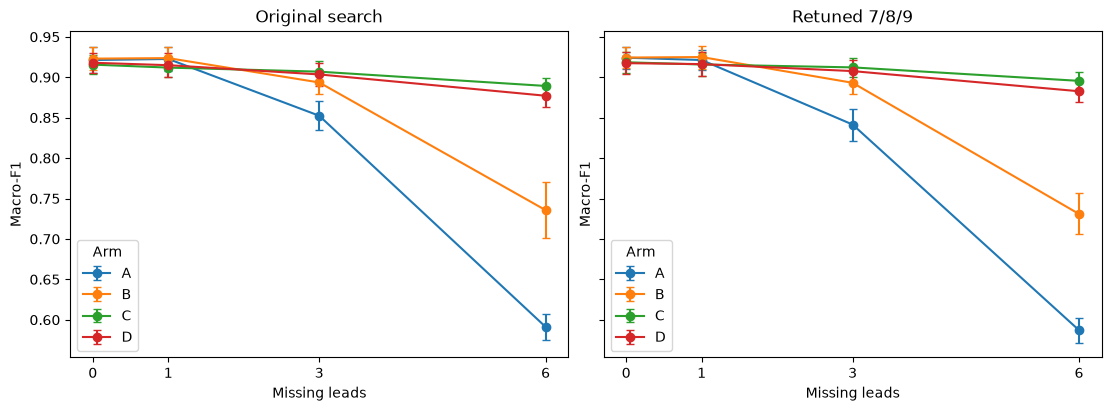

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
conditions = ['observed', 'missing_1', 'missing_3', 'missing_6']
for axis, experiment in zip(axes, ['Original search', 'Retuned 7/8/9']):
    subset = fold_means.loc[fold_means.experiment.eq(experiment)]
    for arm in 'ABCD':
        summary = subset.loc[subset.arm.eq(arm)].groupby('scenario').macro_f1.agg(['mean', 'std']).reindex(conditions)
        axis.errorbar([0, 1, 3, 6], summary['mean'], yerr=summary['std'], marker='o', capsize=3, label=arm)
    axis.set(title=experiment, xlabel='Missing leads', xticks=[0, 1, 3, 6], ylabel='Macro-F1')
    axis.legend(title='Arm')
plt.show()
